# **Rent Price Prediction using Linear Regression**
BBA2063 Business Intelligence for Finance

**Objective:** build and evaluate a linear regression model that predicts monthly house **rent** from property features (size, BHK, bathrooms, floor, city, furnishing, etc.).

#**Data Exploration**

##Mount Google Drive

In [1]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**Code Explanation:**
* This code mounts Google Drive to the Colab environment so the dataset stored in Drive can be read.
* Requires user authentication.
* Files are accessed at '/content/drive/MyDrive'.

##Import Necessary Libraries

In [2]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

**Code Explanation:**
* `re` — regular expressions, used to parse the Floor column.
* `numpy (np)` — numerical computations and the log / exp transformations.
* `pandas (pd)` — data manipulation using DataFrames.
* `matplotlib.pyplot (plt)` and `seaborn (sns)` — visualizations.
* `train_test_split` — splits data into training and testing sets.
* `GridSearchCV` — searches hyperparameter combinations with cross-validation.
* `cross_val_score` — evaluates a model with k-fold cross-validation.
* `ColumnTransformer`, `Pipeline` — chain preprocessing and modeling into one object so that nothing is learned from the test set.
* `SimpleImputer`, `StandardScaler`, `OneHotEncoder` — fill missing values, standardize numbers, and convert categories into 0/1 columns.
* `PolynomialFeatures` — squared and interaction terms for polynomial regression.
* `LinearRegression, Ridge, Lasso, ElasticNet` — regression models.
* `mean_absolute_error, mean_squared_error, r2_score` — evaluation metrics.

##Load and Inspect the Dataset

In [3]:
# Load Dataset (change the path to where you saved the file in your Drive)
df = pd.read_csv('/content/drive/MyDrive/BBA2063_Business Intelligence for Finance/House_Rent_Dataset.csv')

# Print the first 5 rows of data
print("First 5 rows of the Data:")
print(df.head())

# Dataset Overview
print("\nDataset Information:")
df.info()

# Summary Statistics
print("\nSummary Statistics:")
print(df.describe())

# Checking for Missing Values and Duplicates
print("\nMissing Values per Column:")
print(df.isnull().sum())
print("\nDuplicate rows (ignoring ID):", df.drop(columns='ID').duplicated().sum())

# Number of listings per city
print("\nListings per City:")
print(df['City'].value_counts())

First 5 rows of the Data:
   ID  Posted On  BHK   Rent  Size            Floor    Area Type  \
0   1  18/5/2022    2  10000  1100  Ground out of 2   Super Area   
1   2  13/5/2022    2  20000   800       1 out of 3   Super Area   
2   3  16/5/2022    2  17000  1000       1 out of 3   Super Area   
3   4   4/7/2022    2  10000   800       1 out of 2   Super Area   
4   5   9/5/2022    2   7500   850       1 out of 2  Carpet Area   

              Area Locality     City Furnishing Status  Tenant Preferred  \
0                    Bandel  Kolkata       Unfurnished  Bachelors/Family   
1  Phool Bagan, Kankurgachi  Kolkata    Semi-Furnished  Bachelors/Family   
2   Salt Lake City Sector 2  Kolkata    Semi-Furnished  Bachelors/Family   
3               Dumdum Park  Kolkata       Unfurnished  Bachelors/Family   
4             South Dum Dum  Kolkata       Unfurnished         Bachelors   

   Bathroom Point of Contact  
0         2    Contact Owner  
1         1    Contact Owner  
2         1    

**Code Explanation:**
* `pd.read_csv()` reads the CSV file into a DataFrame stored in `df`.
* `df.head()` shows the first 5 rows; `df.info()` shows column names, data types and non-null counts.
* `df.describe()` gives the mean, standard deviation, minimum, maximum and percentiles of the numeric columns.
* `df.isnull().sum()` counts missing values per column. This dataset has no missing values.
* The dataset has 4,746 rental listings from 6 cities. The target variable is **Rent**.
* The brief mentions "house prices", crime rate and distance to public transport. Our dataset contains rental listings and does not have those columns, so we predict **Rent** using the features that are available.
* In the summary statistics, the mean Rent (about 35,000) is far above the median (16,000) and the maximum is 3,500,000, which signals a strongly right-skewed target. Size also ranges from 10 to 8,000 sq ft, so some values look suspicious.

##Visualizations

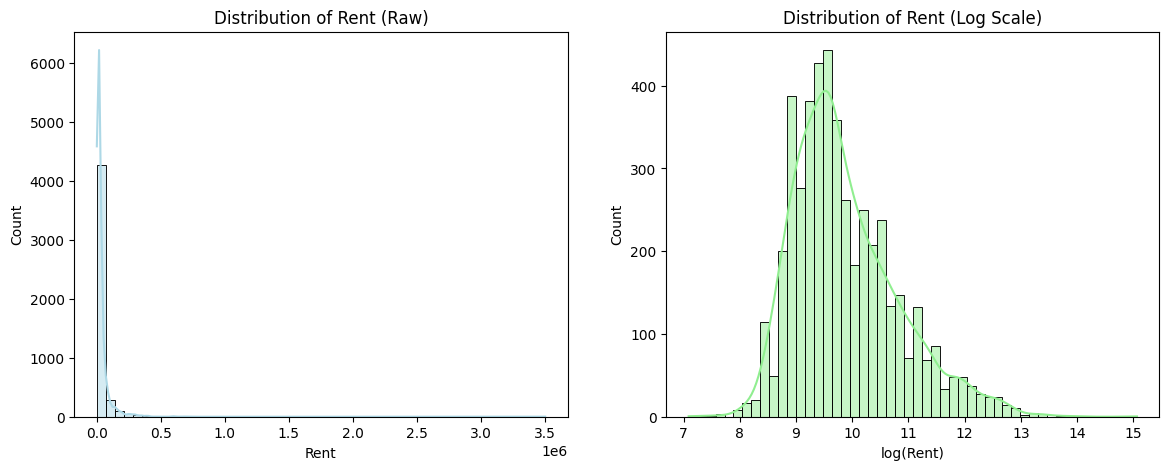

Skewness (raw): 21.41 | Skewness (log): 0.91


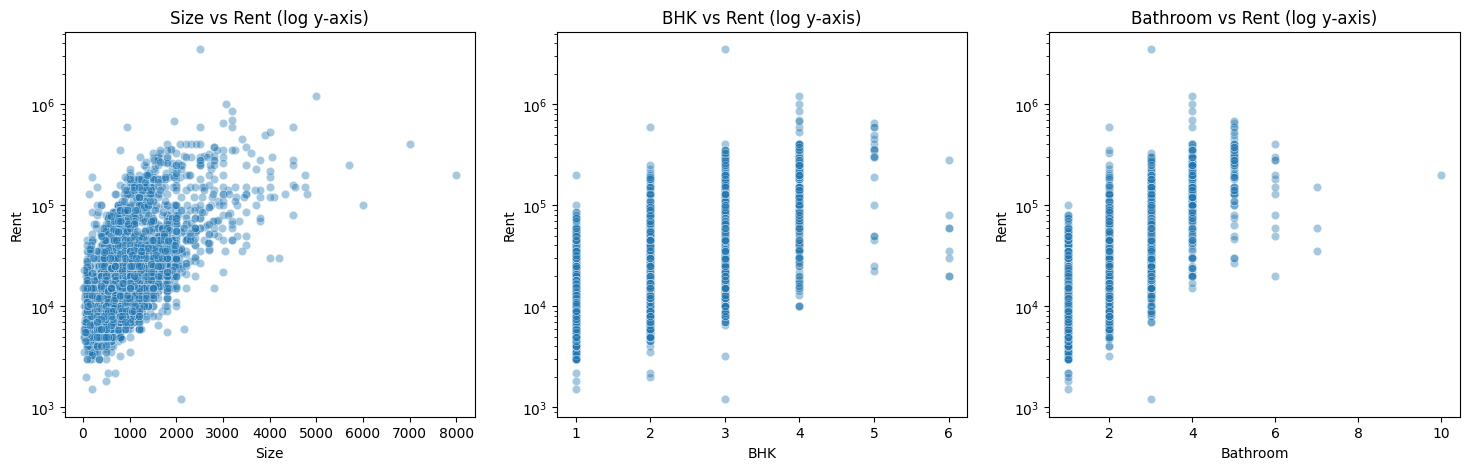

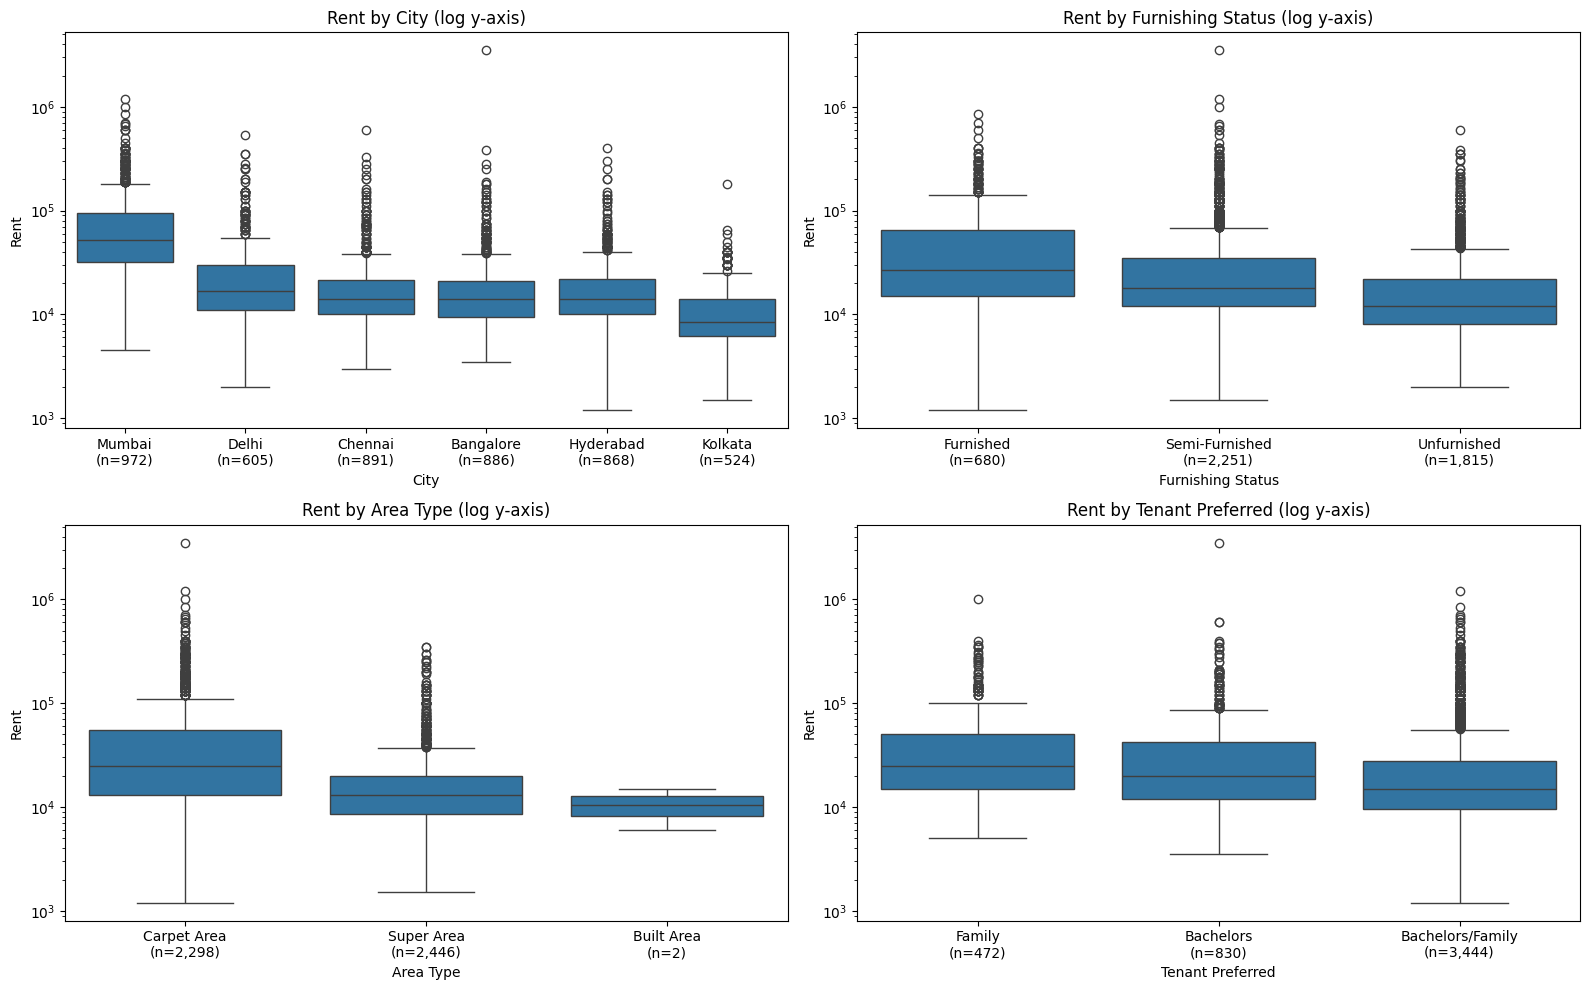

           count   median     mean
City                              
Mumbai       972  52000.0  85321.0
Delhi        605  17000.0  29462.0
Chennai      891  14000.0  21614.0
Bangalore    886  14000.0  24966.0
Hyderabad    868  14000.0  20555.0
Kolkata      524   8500.0  11645.0


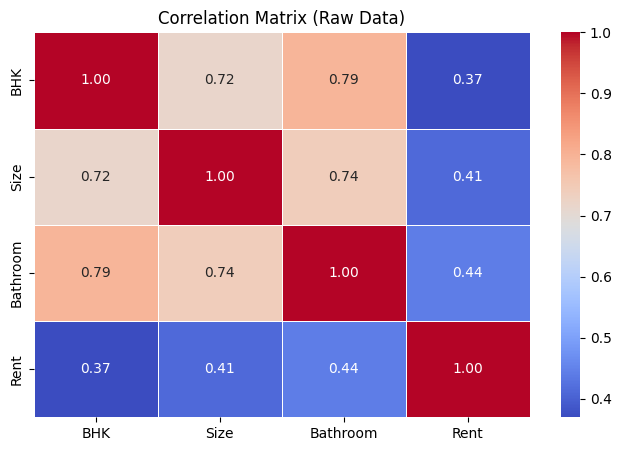

In [4]:
# Distribution of the Target Variable (raw and log scale)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df['Rent'], kde=True, color='lightblue', bins=50, ax=axes[0])
axes[0].set_title('Distribution of Rent (Raw)')
axes[0].set_xlabel('Rent')
sns.histplot(np.log(df['Rent']), kde=True, color='lightgreen', bins=50, ax=axes[1])
axes[1].set_title('Distribution of Rent (Log Scale)')
axes[1].set_xlabel('log(Rent)')
plt.show()
print(f"Skewness (raw): {df['Rent'].skew():.2f} | Skewness (log): {np.log(df['Rent']).skew():.2f}")

# Relationships between numeric features and Rent (log scale on y-axis)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, ['Size', 'BHK', 'Bathroom']):
    sns.scatterplot(x=col, y='Rent', data=df, alpha=0.4, ax=ax)
    ax.set_yscale('log')
    ax.set_title(f'{col} vs Rent (log y-axis)')
plt.show()

# Boxplots of Rent across categorical features
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, col in zip(axes.flat, ['City', 'Furnishing Status', 'Area Type', 'Tenant Preferred']):
    order = df.groupby(col)['Rent'].median().sort_values(ascending=False).index
    sns.boxplot(x=col, y='Rent', data=df, order=order, ax=ax)
    ax.set_yscale('log')
    ax.set_title(f'Rent by {col} (log y-axis)')
    # Show the number of listings (n) under each category label
    counts = df[col].value_counts()
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels([f"{c}\n(n={counts[c]:,})" for c in order])
plt.tight_layout()
plt.show()

# Median rent by city
print(df.groupby('City')['Rent'].agg(['count', 'median', 'mean']).sort_values('median', ascending=False).round(0))

# Correlation Matrix
plt.figure(figsize=(8, 5))
correlation_matrix = df[['BHK', 'Size', 'Bathroom', 'Rent']].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix (Raw Data)')
plt.show()

**Code Explanation:**
* Distribution of the Target Variable
  * `sns.histplot(..., kde=True)` draws a histogram with a Kernel Density Estimate curve.
  * The raw Rent is heavily right-skewed (skewness about 21): most listings are in the lower range and a few very expensive properties stretch the tail. After taking the **log**, the distribution is much closer to symmetric (skewness about 0.9).
  * Linear regression works best when the errors are roughly symmetric and have similar spread, so we will model **log(Rent)** later.
* Numeric Features vs Rent
  * `ax.set_yscale('log')` puts rent on a log axis so the dense lower-priced listings can be seen.
  * Rent rises with Size, BHK and Bathroom. A few points at very small or very large Size look like data-entry errors and are handled in preprocessing.
* Boxplots of Categorical Features
  * Boxplots show the median, interquartile range (IQR) and potential outliers of Rent for each category.
  * The number of listings (n) is shown under each category label. 'Built Area' has only 2 listings, so its box should not be interpreted; it is merged into 'Carpet Area' during preprocessing.
  * City has the largest effect: Mumbai is far more expensive than the other cities and Kolkata is the cheapest. Furnished properties also tend to rent for more.
* Correlation Matrix
  * `.corr()` computes the Pearson correlation between numeric columns and `sns.heatmap()` visualizes it.
  * Bathroom, BHK and Size are all positively correlated with Rent, and they are also correlated with each other (larger homes have more rooms and bathrooms). This is checked later with VIF.
  * Categorical columns cannot be included in a Pearson correlation heatmap, which is why they are explored with boxplots instead.

# **Data Preprocessing**

##Checking Point of Contact Before Dropping It

In [5]:
# Is 'Point of Contact' an independent driver of rent, or mainly a proxy for city?
print("Share of listings by Point of Contact within each City:")
print(pd.crosstab(df['City'], df['Point of Contact'], normalize='index').round(2))

print("\nMedian Rent by Point of Contact (all cities):")
print(df.groupby('Point of Contact')['Rent'].median())

print("\nMedian Rent by Point of Contact (excluding Mumbai):")
print(df[df['City'] != 'Mumbai'].groupby('Point of Contact')['Rent'].median())

Share of listings by Point of Contact within each City:
Point of Contact  Contact Agent  Contact Builder  Contact Owner
City                                                           
Bangalore                  0.21              0.0           0.79
Chennai                    0.15              0.0           0.85
Delhi                      0.40              0.0           0.60
Hyderabad                  0.13              0.0           0.87
Kolkata                    0.15              0.0           0.85
Mumbai                     0.80              0.0           0.20

Median Rent by Point of Contact (all cities):
Point of Contact
Contact Agent      45000.0
Contact Builder     5500.0
Contact Owner      12500.0
Name: Rent, dtype: float64

Median Rent by Point of Contact (excluding Mumbai):
Point of Contact
Contact Agent      29000.0
Contact Builder     5500.0
Contact Owner      12000.0
Name: Rent, dtype: float64


**Code Explanation:**
* `pd.crosstab(..., normalize='index')` shows, for each city, the share of listings handled by an agent, owner or builder.
* About 80% of Mumbai listings are posted by agents, compared with roughly 13–21% in Bangalore, Chennai, Hyderabad and Kolkata (Delhi is about 40%). Agent listings are therefore concentrated in the most expensive city.
* Agent listings have a much higher median rent than owner listings overall, but the gap shrinks when Mumbai is excluded. This means a large part of the "agent premium" is really a **city effect**.
* Some difference remains outside Mumbai, so the column is not purely a proxy for city. Even so, who posts the listing is not something that makes a property cost more; it mostly reflects where and what type of property it is.
* Decision: `Point of Contact` is dropped because City is already in the model, and keeping both would double-count location and make the City coefficients harder to interpret. Whether it adds anything beyond City could be tested in future work.

##Floor Column Parsing and Dropping Irrelevant Columns

In [6]:
# Parse the Floor column, e.g. "3 out of 10", "Ground out of 2", "1"
# Unit floor = number BEFORE "out of"; total floors = number AFTER "out of"
def parse_floor(value):
    s = str(value).strip().lower()
    if 'ground' in s:
        unit = 0.0
    elif 'basement' in s:
        unit = -1.0
    else:
        m = re.match(r'\s*(\d+)', s)
        unit = float(m.group(1)) if m else np.nan
    t = re.search(r'out of\s*(\d+)', s)
    total = float(t.group(1)) if t else np.nan
    return unit, total

parsed = df['Floor'].apply(parse_floor)
df['Floor'] = [p[0] for p in parsed]
df['Total Floors'] = [p[1] for p in parsed]

# Drop columns that do not contribute to prediction
df = df.drop(columns=['ID', 'Posted On', 'Point of Contact', 'Area Locality'])

# Group extremely rare categories (only 2 rows of 'Built Area')
df['Area Type'] = df['Area Type'].replace({'Built Area': 'Carpet Area'})

print("Remaining columns:", df.columns.tolist())
print("\nMissing values after parsing:")
print(df.isnull().sum())

Remaining columns: ['BHK', 'Rent', 'Size', 'Floor', 'Area Type', 'City', 'Furnishing Status', 'Tenant Preferred', 'Bathroom', 'Total Floors']

Missing values after parsing:
BHK                  0
Rent                 0
Size                 0
Floor                0
Area Type            0
City                 0
Furnishing Status    0
Tenant Preferred     0
Bathroom             0
Total Floors         4
dtype: int64


**Code Explanation:**
* Floor Parsing
  * The Floor column is text such as "3 out of 10" or "Ground out of 2". The `parse_floor()` function creates two numeric columns: the unit's floor (before "out of") and the building's total floors (after "out of").
  * "Ground" is mapped to 0 and "Basement" to -1.
  * A few rows have no "out of" part, so their Total Floors becomes NaN. These are imputed later inside the training pipeline.
* Dropping Columns
  * 'ID' and 'Posted On' are identifiers or date metadata with no predictive value (the data covers only a few months).
  * 'Point of Contact' is dropped because it is largely tied to city (see the check above), and City is already in the model.
  * 'Area Locality' has more than 2,000 unique values. One-hot encoding it would create thousands of columns, and label-encoding would give arbitrary numbers that linear regression treats as an ordered scale, which is meaningless.
* Rare Categories
  * 'Built Area' has only 2 rows, which is too few to learn from, so it is merged into 'Carpet Area'.

##Outlier Handling

count    4746.00
mean       39.26
std        59.86
min         0.57
25%        13.33
50%        20.00
75%        42.01
max      1500.00
Name: Rent per SqFt, dtype: float64

Implausible size: 95 | Implausible rent per sq ft: 20
Rows removed: 107 (2.3%) | Rows remaining: 4639


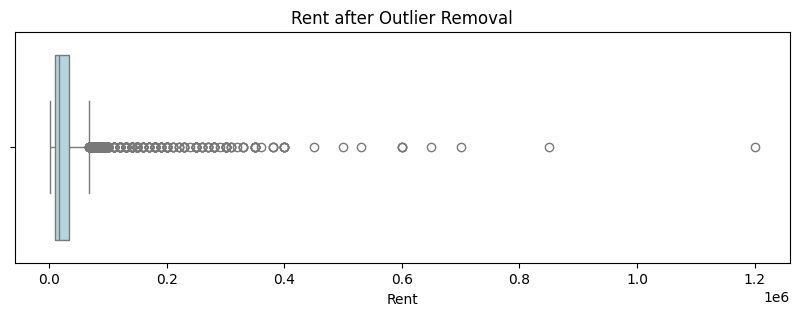

In [7]:
# Rent per square foot helps to spot impossible listings
df['Rent per SqFt'] = df['Rent'] / df['Size']
print(df['Rent per SqFt'].describe().round(2))

# Rule-based outlier detection (fixed thresholds, so no information is taken from the test set)
size_outlier = (df['Size'] < 100) | (df['Size'] > 5000)
ppsf_outlier = (df['Rent per SqFt'] < 2) | (df['Rent per SqFt'] > 300)
print("\nImplausible size:", size_outlier.sum(), "| Implausible rent per sq ft:", ppsf_outlier.sum())

rows_before = len(df)
df = df[~(size_outlier | ppsf_outlier)].drop(columns='Rent per SqFt').reset_index(drop=True)
print(f"Rows removed: {rows_before - len(df)} ({(rows_before - len(df)) / rows_before:.1%}) | Rows remaining: {len(df)}")

# Boxplot of Rent after cleaning
plt.figure(figsize=(10, 3))
sns.boxplot(x=df['Rent'], color='lightblue')
plt.title('Rent after Outlier Removal')
plt.show()

**Code Explanation:**
* Rent per square foot (`Rent / Size`) is calculated to find listings whose numbers do not make sense together.
* Records are removed when the Size is below 100 sq ft or above 5,000 sq ft (not a normal rental), or when Rent per sq ft is below 2 or above 300 (very likely data-entry errors, e.g. a 20 sq ft flat renting for 5,000).
* Fixed rules are used instead of percentiles so that no statistics are learned from the full dataset before the train–test split.
* Only about 2% of the rows are removed.
* Expensive but plausible properties (e.g. large Mumbai flats) are **kept**. They are real observations, and taking the log of Rent reduces their influence on the model.

##Train–Test Split (Before Any Preprocessing)

In [8]:
# Define features and target
target = 'Rent'
X = df.drop(columns=[target])
y = df[target]
y_log = np.log(y)          # the model is trained on log(Rent)

numeric_features = ['BHK', 'Size', 'Bathroom', 'Floor', 'Total Floors']
categorical_features = ['Area Type', 'Furnishing Status', 'Tenant Preferred', 'City']

# Split the data: 80% training, 20% testing
X_train, X_test, y_train_log, y_test_log = train_test_split(
    X, y_log, test_size=0.2, random_state=42
)
y_test = np.exp(y_test_log)   # actual rent in original currency, for reporting

print(f"Train size: {X_train.shape}, Test size: {X_test.shape}")

Train size: (3711, 9), Test size: (928, 9)


**Code Explanation:**
* Features (`X`): all columns except 'Rent'. Target (`y`): the 'Rent' column.
* The target is transformed with `np.log()` because of its strong right skew. Predictions are converted back with `np.exp()` so that MAE and RMSE are reported in actual rent (currency) units.
* The split is performed **before** the scaling, encoding and imputation steps, so the test set stays unseen. If preprocessing were applied to the full dataset first, information from the test set would leak into training and inflate the scores.
* `random_state=42` makes the split reproducible.

##Preprocessing Pipeline

In [9]:
# Numeric features: impute missing values with the median, then standardize
numeric_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])

# Categorical features: impute with the most frequent value, then one-hot encode
categorical_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore')),
])

# Combine into a ColumnTransformer
preprocess = ColumnTransformer([
    ('num', numeric_pipe, numeric_features),
    ('cat', categorical_pipe, categorical_features),
])

**Code Explanation:**
* Numeric Pipeline
  * `SimpleImputer(strategy='median')` fills missing numeric values (e.g. Total Floors) with the median.
  * `StandardScaler()` standardizes each feature to mean 0 and standard deviation 1. Plain linear regression does not need scaling, but Ridge/Lasso penalties do, and scaling lets coefficients be compared.
* Categorical Pipeline
  * `SimpleImputer(strategy='most_frequent')` fills missing categories with the most common value.
  * `OneHotEncoder(drop='first')` converts each category into 0/1 columns and drops the first category to avoid the dummy variable trap. Each dummy is interpreted relative to the dropped baseline category.
  * `handle_unknown='ignore'` prevents errors if the test set has a category not seen in training.
* `ColumnTransformer` applies each pipeline to its columns inside a single object that is fitted on the training data only.

#**Feature Selection and Transformation**

##Feature Relevance

In [10]:
# Relevance of numeric features: correlation with log(Rent) on the training set
train_df = X_train[numeric_features].copy()
train_df['log(Rent)'] = y_train_log
print("Correlation with log(Rent) (training data):")
print(train_df.corr()['log(Rent)'].drop('log(Rent)').sort_values(ascending=False).round(3))

# Relevance of categorical features: median rent per category
for col in categorical_features:
    print(f"\nMedian Rent by {col}:")
    print(np.exp(y_train_log).groupby(X_train[col]).median().round(0))

Correlation with log(Rent) (training data):
Bathroom        0.693
BHK             0.600
Size            0.572
Total Floors    0.563
Floor           0.500
Name: log(Rent), dtype: float64

Median Rent by Area Type:
Area Type
Carpet Area    25000.0
Super Area     13000.0
Name: Rent, dtype: float64

Median Rent by Furnishing Status:
Furnishing Status
Furnished         27500.0
Semi-Furnished    18000.0
Unfurnished       12000.0
Name: Rent, dtype: float64

Median Rent by Tenant Preferred:
Tenant Preferred
Bachelors           20000.0
Bachelors/Family    15000.0
Family              25000.0
Name: Rent, dtype: float64

Median Rent by City:
City
Bangalore    14500.0
Chennai      14000.0
Delhi        18000.0
Hyderabad    14500.0
Kolkata       8500.0
Mumbai       52000.0
Name: Rent, dtype: float64


**Code Explanation:**
* Numeric features are ranked by their correlation with log(Rent), computed on the training data only.
* For categorical features, the median rent of each category is compared. A feature is useful when the medians differ clearly between categories.
* Bathroom, BHK, Size and Total Floors show the strongest positive relationships with rent (correlations of roughly 0.55 to 0.70). Floor also correlates with rent, but later its coefficient turns out to be almost zero, because it overlaps with Total Floors.
* City shows the largest differences between categories (Mumbai's median is about 6 times Kolkata's), followed by Furnishing Status. Area Type and Tenant Preferred also differ, but partly because of the cities and sizes they happen to be associated with.
* All of these features are kept, because there are only a few of them. Weak features are checked again with the coefficients and Lasso later.

##Variance Inflation Factor (VIF)

In [11]:
# Compute VIF on the transformed TRAINING numeric data only
# VIF of a feature = 1 / (1 - R²) when it is predicted from all the other features
X_num = pd.DataFrame(
    numeric_pipe.fit_transform(X_train[numeric_features]), columns=numeric_features
)

vif_values = {}
for col in numeric_features:
    others = X_num.drop(columns=col)
    r2 = LinearRegression().fit(others, X_num[col]).score(others, X_num[col])
    vif_values[col] = 1 / (1 - r2)

print(pd.Series(vif_values, name='VIF').sort_values(ascending=False).round(2))

Total Floors    4.10
Floor           4.00
Bathroom        3.56
BHK             3.25
Size            2.65
Name: VIF, dtype: float64


**Code Explanation:**
* VIF measures how much a feature is linearly explained by the other features. Conventional concern levels are VIF above 5–10.
* It is computed on the training data only, for the numeric features. VIF on one-hot dummies is not meaningful because dummies from the same column are structurally related.
* All VIF values are below 5 (the highest is about 4.1, for Total Floors), so multicollinearity is moderate rather than severe even though BHK, Bathroom and Size are correlated. All numeric features can stay in the model.
* VIF is used as a diagnostic rather than an automatic feature-deletion rule.

##Feature Transformation

**Transformations used in this project:**
* **Log transform of the target (Rent):** fixes the strong right skew and makes the errors more even across cheap and expensive properties. It also changes how coefficients are read: a coefficient `b` means rent changes by about `(e^b - 1) × 100` percent.
* **Floor parsing:** converts a messy text column into two numeric features (unit floor and total floors).
* **Standardization and one-hot encoding:** handled inside the preprocessing pipeline.
* **Polynomial features (degree 2):** tested in the Model Building section to see whether squared and interaction terms (e.g. Size × City) improve the model. (Result: they do not improve it in a meaningful way.)

#**Model Building**

##Define the Evaluation Function

In [12]:
def evaluate_model(y_true_log, y_pred_log, model_name):
    # Convert log predictions back to actual rent before computing metrics
    y_true, y_pred = np.exp(y_true_log), np.exp(y_pred_log)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    r2_log = r2_score(y_true_log, y_pred_log)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    print(f"\n{model_name}:")
    print(f"  MAE:    {mae:,.2f}")
    print(f"  RMSE:   {rmse:,.2f}")
    print(f"  MAPE:   {mape:.2f}%")
    print(f"  R²:     {r2:.4f}  (actual rent)")
    print(f"  R² log: {r2_log:.4f}  (log scale)")
    return {'Model': model_name, 'MAE': mae, 'RMSE': rmse, 'MAPE %': mape, 'R2': r2, 'R2 (log)': r2_log}

results = []

**Code Explanation:**
* MAE: the average absolute error in rent units. RMSE: like MAE but penalizes large errors more.
* MAPE: the average percentage error, which is the easiest metric to explain to non-technical readers.
* R²: the share of variation in rent explained by the model. It is reported on the actual rent scale and on the log scale (the scale the model was trained on).
* The function first converts predictions from log scale back to actual rent with `np.exp()`, so MAE and RMSE are in currency units.
* The function returns a dictionary so all results can be collected into one summary table.

##Linear Regression

In [13]:
# Linear Regression within a preprocessing pipeline
lr_pipe = Pipeline([('prep', preprocess), ('reg', LinearRegression())])
lr_pipe.fit(X_train, y_train_log)
results.append(evaluate_model(y_test_log, lr_pipe.predict(X_test), "Linear Regression"))

# Comparison: the same model trained on raw Rent (no log transform)
raw_pipe = Pipeline([('prep', preprocess), ('reg', LinearRegression())])
raw_pipe.fit(X_train, np.exp(y_train_log))
raw_pred = raw_pipe.predict(X_test)
print(f"\nLinear Regression on RAW Rent -> R²: {r2_score(y_test, raw_pred):.4f}, "
      f"MAE: {mean_absolute_error(y_test, raw_pred):,.2f}, "
      f"negative predictions: {(raw_pred < 0).sum()}")


Linear Regression:
  MAE:    11,642.31
  RMSE:   31,567.77
  MAPE:   32.21%
  R²:     0.7014  (actual rent)
  R² log: 0.8297  (log scale)

Linear Regression on RAW Rent -> R²: 0.5675, MAE: 20,909.24, negative predictions: 189


**Code Explanation:**
* A `Pipeline` chains preprocessing and Linear Regression, so preprocessing is fitted on the training data only.
* The model is trained on log(Rent) and evaluated on the test set in actual rent units.
* As a comparison, the same model is trained on raw Rent. The log version gives a clearly better R² and a much lower MAE, and the raw model even predicts negative rents for many test listings. This supports the decision to use the log transform.

##Ridge, Lasso, and ElasticNet with Hyperparameter Tuning

In [14]:
# Ridge, Lasso, and ElasticNet with GridSearchCV
# Preprocessing is inside the pipeline, so GridSearchCV re-fits it on each fold (no leakage)
param_grids = {
    'Ridge':      (Ridge(),                {'reg__alpha': [0.01, 0.1, 1, 10, 100]}),
    'Lasso':      (Lasso(max_iter=10000),  {'reg__alpha': [0.0001, 0.001, 0.01, 0.1, 1]}),
    'ElasticNet': (ElasticNet(max_iter=10000),
                   {'reg__alpha': [0.0001, 0.001, 0.01, 0.1, 1],
                    'reg__l1_ratio': [0.2, 0.5, 0.8]}),
}

best_models = {}
for name, (model, grid) in param_grids.items():
    pipe = Pipeline([('prep', preprocess), ('reg', model)])
    search = GridSearchCV(pipe, grid, cv=5, scoring='neg_mean_squared_error', n_jobs=-1)
    search.fit(X_train, y_train_log)
    best_models[name] = search.best_estimator_
    print(f"\nBest params for {name}: {search.best_params_}")
    results.append(evaluate_model(y_test_log, search.predict(X_test), f"{name} Regression"))


Best params for Ridge: {'reg__alpha': 1}

Ridge Regression:
  MAE:    11,642.45
  RMSE:   31,551.71
  MAPE:   32.20%
  R²:     0.7017  (actual rent)
  R² log: 0.8298  (log scale)

Best params for Lasso: {'reg__alpha': 0.0001}

Lasso Regression:
  MAE:    11,638.40
  RMSE:   31,544.85
  MAPE:   32.20%
  R²:     0.7019  (actual rent)
  R² log: 0.8297  (log scale)

Best params for ElasticNet: {'reg__alpha': 0.0001, 'reg__l1_ratio': 0.8}

ElasticNet Regression:
  MAE:    11,639.20
  RMSE:   31,548.25
  MAPE:   32.20%
  R²:     0.7018  (actual rent)
  R² log: 0.8297  (log scale)


**Code Explanation:**
* Ridge adds an L2 penalty that shrinks coefficients. Lasso adds an L1 penalty that can shrink some coefficients to exactly zero (implicit feature selection). ElasticNet mixes both, controlled by `l1_ratio`.
* `GridSearchCV` tries every combination in the grid using 5-fold cross-validation on the **training set** and keeps the best one. `scoring='neg_mean_squared_error'` selects the setting with the lowest error (on the log scale).
* `max_iter=10000` helps Lasso and ElasticNet converge.
* This addresses model complexity and hyperparameter tuning: the penalty strength (`alpha`) controls how much the coefficients are shrunk.
* The tuned models perform almost the same as plain Linear Regression. This means the model is not overfitting, because there are only a few features and a few thousand rows, so regularization has little to fix.

##Polynomial Regression (Degree 2)

In [15]:
# Polynomial Regression: adds squared terms and pairwise interactions
poly_pipe = Pipeline([
    ('prep', preprocess),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('reg', Ridge(alpha=10)),
])
poly_pipe.fit(X_train, y_train_log)
y_pred_poly = poly_pipe.predict(X_test)
results.append(evaluate_model(y_test_log, y_pred_poly, "Polynomial Regression (deg 2, Ridge)"))

# Overfitting check: compare training and test R² (log scale)
print(f"\nPolynomial train R²: {poly_pipe.score(X_train, y_train_log):.4f}")
print(f"Polynomial test  R²: {poly_pipe.score(X_test, y_test_log):.4f}")
print(f"Linear     train R²: {lr_pipe.score(X_train, y_train_log):.4f}")
print(f"Linear     test  R²: {lr_pipe.score(X_test, y_test_log):.4f}")


Polynomial Regression (deg 2, Ridge):
  MAE:    11,913.92
  RMSE:   43,394.32
  MAPE:   32.42%
  R²:     0.4358  (actual rent)
  R² log: 0.8307  (log scale)

Polynomial train R²: 0.8325
Polynomial test  R²: 0.8307
Linear     train R²: 0.8108
Linear     test  R²: 0.8297


**Code Explanation:**
* `PolynomialFeatures(degree=2)` creates squared terms and pairwise interactions (e.g. Size × Bathroom, or Size × a city dummy) so the model can capture non-linear effects and different size effects in different cities.
* This creates many more features, so a mild Ridge penalty (`alpha=10`) is used to keep the model stable.
* Training R² is compared with test R² to check for overfitting. A large gap would mean the model is memorizing the training data.
* On the log scale the polynomial model is almost identical to the linear model (R² about 0.831 vs 0.830). On the actual rent scale it is clearly **worse** (R² about 0.44 vs 0.70), because a few extreme over-predictions on the log scale become very large errors once converted back to rupees. The extra complexity therefore brings no real benefit.

##Cross-Validation Stability Check

In [16]:
# Evaluate the models with 5-fold cross-validation on the training set (log scale R²)
for name, model in [('Linear', lr_pipe), ('Polynomial (deg 2, Ridge)', poly_pipe)]:
    cv_scores = cross_val_score(model, X_train, y_train_log, cv=5, scoring='r2')
    print(f"{name}: CV R² = {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")

Linear: CV R² = 0.8093 ± 0.0101
Polynomial (deg 2, Ridge): CV R² = 0.8200 ± 0.0134


**Code Explanation:**
* A single 80/20 split depends on which rows happened to land in the test set. `cross_val_score` splits the training data into 5 folds, trains on 4 and validates on 1, and repeats 5 times.
* The mean CV R² shows the expected performance and the standard deviation shows how much it varies across splits.
* The polynomial model scores slightly higher than the linear model in cross-validation (about 0.82 vs 0.81), but the ranges overlap, so the difference is modest rather than significant.
* Combined with its worse test performance on the actual rent scale, this means the simpler Linear Regression is the better choice.

##Model Coefficients

Model Coefficients (sorted by absolute value):
                                        Coefficient  % Change in Rent
cat__City_Mumbai                              1.032           180.558
cat__Furnishing Status_Unfurnished           -0.341           -28.862
num__Size                                     0.307            35.911
cat__City_Kolkata                            -0.286           -24.893
cat__City_Delhi                               0.232            26.125
cat__Furnishing Status_Semi-Furnished        -0.225           -20.120
num__BHK                                      0.170            18.511
cat__City_Hyderabad                          -0.163           -15.032
cat__Area Type_Super Area                    -0.160           -14.762
num__Bathroom                                 0.120            12.800
cat__Tenant Preferred_Family                 -0.119           -11.190
num__Total Floors                             0.081             8.465
cat__Tenant Preferred_Bachelors/Family     

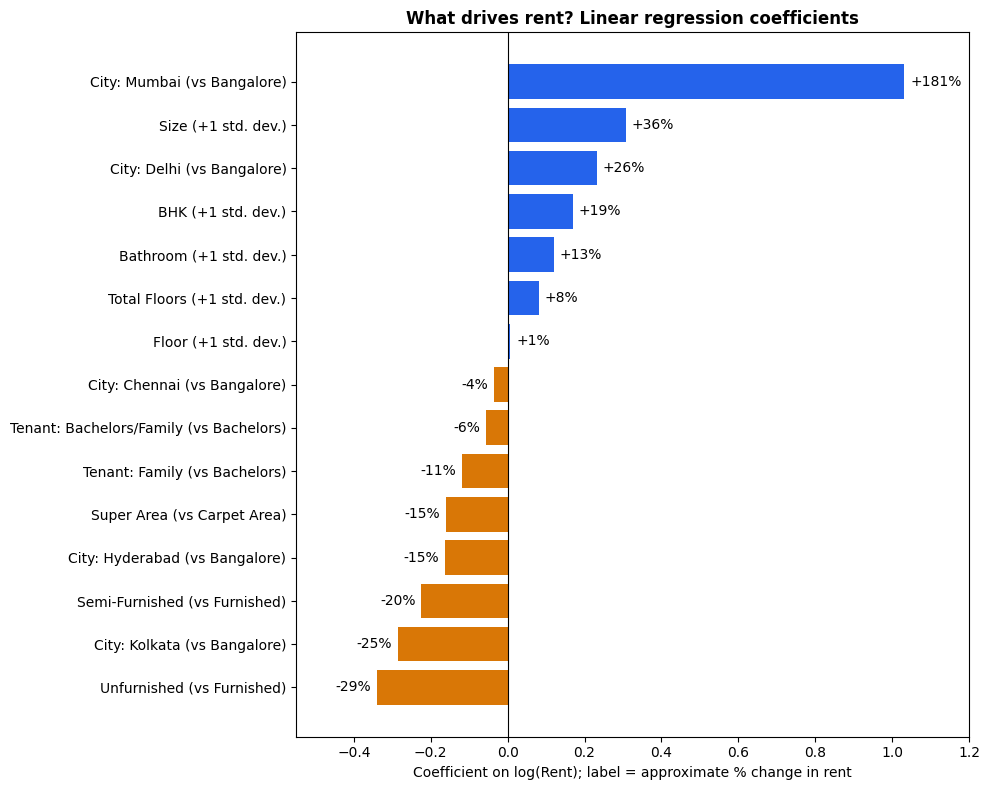

In [17]:
# Coefficients from the Linear Regression model (log-rent target)
feature_names = preprocess.get_feature_names_out()
coefs = pd.Series(lr_pipe.named_steps['reg'].coef_, index=feature_names)
coef_table = pd.DataFrame({
    'Coefficient': coefs,
    '% Change in Rent': (np.exp(coefs) - 1) * 100
}).sort_values('Coefficient', key=abs, ascending=False)

print("Model Coefficients (sorted by absolute value):")
print(coef_table.round(3))

# Readable labels for the chart (the baseline category is shown in brackets)
labels = {
    'num__Size': 'Size (+1 std. dev.)', 'num__BHK': 'BHK (+1 std. dev.)',
    'num__Bathroom': 'Bathroom (+1 std. dev.)', 'num__Floor': 'Floor (+1 std. dev.)',
    'num__Total Floors': 'Total Floors (+1 std. dev.)',
    'cat__City_Mumbai': 'City: Mumbai (vs Bangalore)', 'cat__City_Delhi': 'City: Delhi (vs Bangalore)',
    'cat__City_Chennai': 'City: Chennai (vs Bangalore)', 'cat__City_Hyderabad': 'City: Hyderabad (vs Bangalore)',
    'cat__City_Kolkata': 'City: Kolkata (vs Bangalore)',
    'cat__Furnishing Status_Semi-Furnished': 'Semi-Furnished (vs Furnished)',
    'cat__Furnishing Status_Unfurnished': 'Unfurnished (vs Furnished)',
    'cat__Area Type_Super Area': 'Super Area (vs Carpet Area)',
    'cat__Tenant Preferred_Family': 'Tenant: Family (vs Bachelors)',
    'cat__Tenant Preferred_Bachelors/Family': 'Tenant: Bachelors/Family (vs Bachelors)',
}
plot_coefs = coefs.rename(index=labels).sort_values()
plot_pct = (np.exp(plot_coefs) - 1) * 100

plt.figure(figsize=(10, 8))
plt.barh(plot_coefs.index, plot_coefs.values,
         color=['#2563EB' if v > 0 else '#D97706' for v in plot_coefs.values])
for i, (v, p) in enumerate(zip(plot_coefs.values, plot_pct.values)):
    plt.text(v + (0.015 if v > 0 else -0.015), i, f"{p:+.0f}%",
             va='center', ha='left' if v > 0 else 'right')
plt.axvline(0, color='black', linewidth=0.8)
plt.xlim(-0.55, 1.2)
plt.xlabel('Coefficient on log(Rent); label = approximate % change in rent')
plt.title('What drives rent? Linear regression coefficients', fontweight='bold')
plt.tight_layout()
plt.show()

**Code Explanation:**
* These coefficients come from the Linear Regression model (standardized numeric features, one-hot categorical features, log(Rent) target).
* Because the target is log(Rent), the `% Change in Rent` column converts a coefficient `b` into `(e^b - 1) × 100` percent.
* For standardized numeric features, the value is the percentage change in rent for a 1-standard-deviation increase in that feature, holding the others constant.
* For one-hot features, the value is the percentage difference in rent compared with the dropped baseline category (Area Type: Carpet Area, Furnishing: Furnished, Tenant: Bachelors, City: Bangalore).
* In the chart, blue bars increase rent and orange bars decrease it. The label at the end of each bar is the approximate percentage change in rent, and the baseline category is shown in brackets (for example, "Unfurnished (vs Furnished)").
* `labels` only renames the features to readable text for the chart; the values are the same as in the table above.
* Coefficients describe associations, not causation. They should not be used to interpret the Polynomial model.

##Actual vs Predicted Plot and Residuals

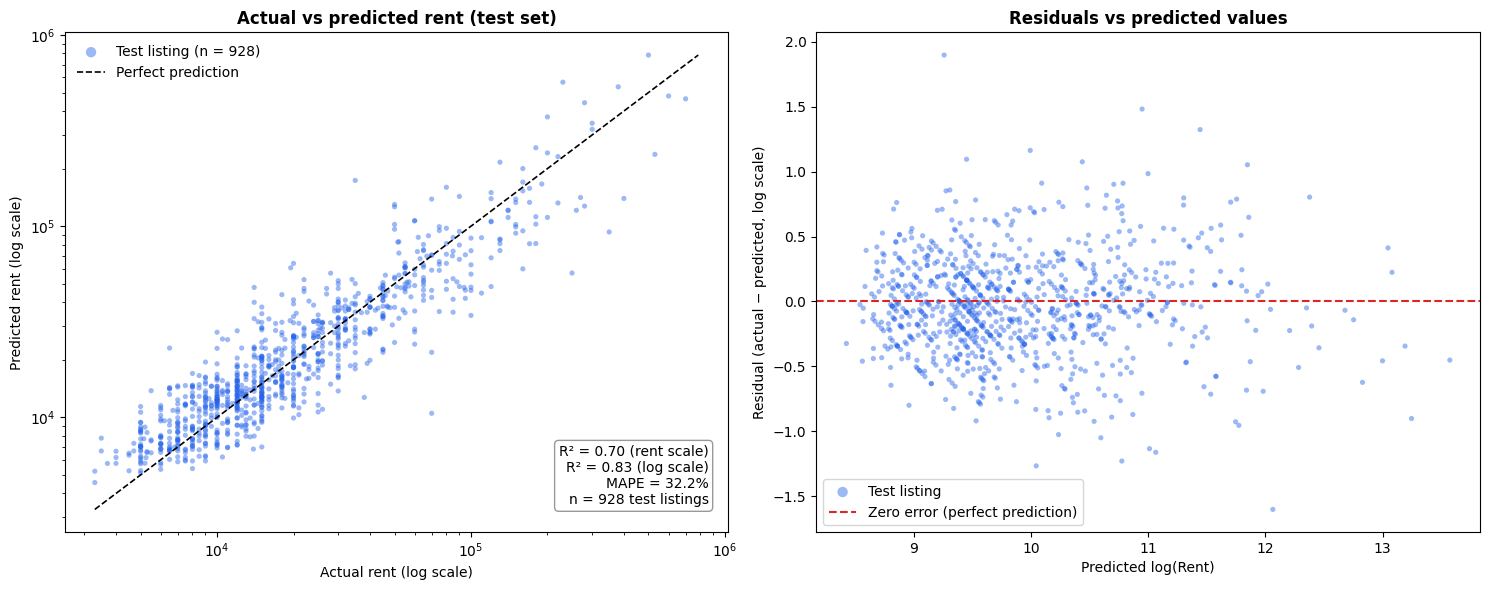

Residual standard deviation by predicted-rent group:
Lowest     0.304
Low        0.363
Middle     0.345
High       0.401
Highest    0.487
dtype: float64


In [18]:
pred_log = lr_pipe.predict(X_test)
pred_lr = np.exp(pred_log)              # predicted rent in original units
resid = y_test_log - pred_log           # residuals on the log scale

# Summary numbers shown on the chart
r2_rent = r2_score(y_test, pred_lr)
r2_log = r2_score(y_test_log, pred_log)
mape = np.mean(np.abs((y_test - pred_lr) / y_test)) * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Left: actual vs predicted (log axes because rent is skewed)
axes[0].scatter(y_test, pred_lr, s=14, alpha=0.45, color='#2563EB', edgecolor='none',
                label=f'Test listing (n = {len(y_test)})')
lo, hi = min(y_test.min(), pred_lr.min()), max(y_test.max(), pred_lr.max())
axes[0].plot([lo, hi], [lo, hi], 'k--', linewidth=1.2, label='Perfect prediction')
axes[0].set_xscale('log'); axes[0].set_yscale('log')
axes[0].set_xlabel('Actual rent (log scale)'); axes[0].set_ylabel('Predicted rent (log scale)')
axes[0].set_title('Actual vs predicted rent (test set)', fontweight='bold')
axes[0].legend(loc='upper left', frameon=False, markerscale=2)
axes[0].text(0.97, 0.05,
             f"R² = {r2_rent:.2f} (rent scale)\nR² = {r2_log:.2f} (log scale)\nMAPE = {mape:.1f}%\nn = {len(y_test)} test listings",
             transform=axes[0].transAxes, ha='right', va='bottom',
             bbox=dict(boxstyle='round', fc='white', ec='#999999'))

# Right: residuals of the Linear Regression model (log scale)
axes[1].scatter(pred_log, resid, s=14, alpha=0.45, color='#2563EB', edgecolor='none', label='Test listing')
axes[1].axhline(0, color='#DC2626', linestyle='--', linewidth=1.5, label='Zero error (perfect prediction)')
axes[1].set_xlabel('Predicted log(Rent)')
axes[1].set_ylabel('Residual (actual − predicted, log scale)')
axes[1].set_title('Residuals vs predicted values', fontweight='bold')
axes[1].legend(loc='lower left', frameon=True, markerscale=2)

plt.tight_layout()
plt.show()

# Residual spread by predicted-rent group (five equal-sized groups, lowest to highest prediction)
groups = pd.qcut(pred_log, 5, labels=['Lowest', 'Low', 'Middle', 'High', 'Highest'])
print("Residual standard deviation by predicted-rent group:")
print(pd.Series(resid.values).groupby(groups, observed=True).std().round(3))

**Code Explanation:**
* Left plot: actual rent (x-axis) against predicted rent (y-axis) for the final Linear Regression model on the test set. The dashed line is y = x, where points are perfect predictions. Log axes are used because rent is skewed. The box summarizes R² (on the rent and log scales), MAPE and the number of test listings.
* The Polynomial model is not plotted here because it was not selected: it performed worse on the rent scale (see the Polynomial Regression section and the final comparison table).
* Points above the line are over-predictions and points below are under-predictions. Each blue point is one test listing.
* Right plot: residuals (actual − predicted, on log scale) against predicted values. The red dashed line marks zero error. A good model shows residuals scattered randomly around zero with no strong pattern.
* The residuals are centred near zero with no strong curve, which supports a linear model on the log scale.
* The table printed below the chart shows that the spread is roughly even but somewhat wider for higher predicted rents (standard deviation about 0.30 in the lowest group and about 0.49 in the highest), so predictions for expensive properties are less precise.

##Error by City

In [19]:
err = pd.DataFrame({'City': X_test['City'].values, 'Actual': y_test.values, 'Predicted': pred_lr})
err['% Error'] = np.abs(err['Actual'] - err['Predicted']) / err['Actual'] * 100
print("Median % error by city (Linear Regression):")
print(err.groupby('City')['% Error'].median().sort_values().round(1))

Median % error by city (Linear Regression):
City
Bangalore    20.9
Mumbai       21.1
Hyderabad    23.9
Kolkata      24.7
Chennai      25.4
Delhi        28.8
Name: % Error, dtype: float64


**Code Explanation:**
* The percentage error of each test prediction is calculated and summarized by city, to see where the model is more or less reliable.
* The median is used because a few extreme listings would distort the mean.
* Errors are lowest in Bangalore and Mumbai (about 21%) and highest in Delhi (about 29%), so they are in a similar range (roughly 21–29%) for all cities.

##Final Results Summary

In [20]:
results_df = pd.DataFrame(results).round(4)
print("\n===== FINAL MODEL COMPARISON (Test Set) =====")
print(results_df.to_string(index=False))


===== FINAL MODEL COMPARISON (Test Set) =====
                               Model        MAE       RMSE  MAPE %     R2  R2 (log)
                   Linear Regression 11642.3091 31567.7650 32.2051 0.7014    0.8297
                    Ridge Regression 11642.4542 31551.7085 32.1974 0.7017    0.8298
                    Lasso Regression 11638.3969 31544.8502 32.1997 0.7019    0.8297
               ElasticNet Regression 11639.1972 31548.2536 32.2002 0.7018    0.8297
Polynomial Regression (deg 2, Ridge) 11913.9248 43394.3233 32.4192 0.4358    0.8307


**Code Explanation:**
* Collects the metrics of all models into one table. MAE and RMSE are in actual rent units, MAPE is a percentage, and R² is unitless.

#**Interpretation and Evaluation**

**1. Interpretation of the Coefficients**

*(Values below come from our run with `random_state=42`; they may differ slightly in your Colab run. Check them against your own coefficient table.)*

* **Location is the strongest driver of rent.** Holding other features constant, a property in Mumbai rents for about 181% more than the Bangalore baseline, Delhi about 26% more, and Kolkata about 25% less. Chennai and Hyderabad are close to Bangalore.
* **Furnishing matters.** Unfurnished homes rent for about 29% less than furnished homes, and semi-furnished homes about 20% less.
* **Size-related features all raise rent.** A 1-standard-deviation increase in Size is associated with about 36% higher rent, in BHK about 19%, and in Bathroom about 13%. Because these three features overlap, the effect of any single one should not be over-interpreted.
* Super Area listings rent for about 15% less than Carpet Area listings, and the unit's own floor has almost no effect once building height and the other features are included.
* All coefficients describe associations, not causal effects.

**2. Assessment of Model Performance**

* All models were evaluated on a held-out test set (20% of the data) that was not used for preprocessing, tuning, or feature decisions.
* Linear Regression on log(Rent) explains about 70% of the variation in rent on the actual scale (R² about 0.70) and about 83% on the log scale. The average prediction error is about 11,600 in rent units, or about 32% (MAPE).
* Ridge, Lasso and ElasticNet performed almost identically to plain Linear Regression, so the model is not overfitting and regularization is not needed here.
* The polynomial model had a similar log-scale R² but was clearly worse in actual rent terms (R² about 0.44), so extra complexity did not help. **Linear Regression is the preferred model**: it is simpler, easier to interpret and more stable.
* The log transform was important: the same model on raw rent reached only R² about 0.57 and produced negative rent predictions.
* Predictions should be treated as a **pricing guide** with a range, not an exact quote.

**3. Implications for Predicting Rent**

* A model like this is useful for benchmarking whether a listing is fairly priced: listings far above their predicted rent may be overpriced, and those far below may be bargains.
* An average error of about 32% is too large for exact valuation. This shows that important rent drivers are missing from the data (building age, exact neighbourhood, amenities, distance to transport).

#**Insights and Recommendations**

* **For landlords and agents:** price mainly according to city, size and furnishing. Furnishing a property can justify a noticeably higher rent.
* **For tenants and analysts:** use the predicted rent as a fair-price benchmark when negotiating or screening listings.
* **For the model owner:** report a prediction range instead of a single number, and retrain regularly because rents change over time.
* **Data collection:** add location detail (coordinates or neighbourhood quality), building age, amenities and distance to public transport.

#**Additional Challenges**

**Challenges found in the dataset and how they were handled**
* **Highly skewed target:** handled with a log transformation, which clearly improved accuracy compared with raw rent.
* **Outliers and data-entry errors:** impossible sizes and rent-per-sq-ft values were removed using fixed rules, while expensive but plausible properties were kept.
* **Messy Floor column:** parsed into unit floor and total floors.
* **High-cardinality locality (2,000+ values):** excluded from this model because one-hot encoding is impractical; it is listed as future work.
* **Correlated size features:** checked with VIF and found acceptable.
* **Rare categories:** 'Built Area' (2 rows) merged with 'Carpet Area'.

**Strategies to improve the model further**
* Encode Area Locality with target encoding or geospatial features (inside cross-validation to avoid leakage).
* Try tree-based models (Random Forest, XGBoost) under the same leakage-free protocol.
* Build separate models per city, since the effect of size differs between cities.
* Add missing drivers such as building age, amenities and distance to transport.

#**Conclusion**

* Rent is strongly right-skewed, so modelling **log(Rent)** gave a much better linear model than raw rent.
* **City, size-related features and furnishing** are the most important predictors.
* Regularization (Ridge, Lasso, ElasticNet) and polynomial terms gave no meaningful gain over plain Linear Regression, so the simple linear model is preferred.
* The final model explains about 70% of rent variation (R² about 0.70 on actual rent, about 0.83 on log scale) with an average error of about 32%, so it is best used as a pricing guide. Richer location data would likely improve it more than further tuning.